# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. train_from_iterator очікує список окремих текстів (у випадку датасету з лекції - віршів). Якщо передати один суцільний рядок, програма читатиме його по одній літері. В результаті тренер отримає більше 60 мільйонів окремих символів і словник складатиметься лише з літер. Якщо ж передати текст як список з одного елемента [corpus_text], токенізатор завантажить усе в пам'ять одночасно. Це викличе проблеми з використанням пам'яті і сповільнить тренування.

2. Токенізація складається з чотирьох етапів:

- Нормалізація, що полягає в обробці сирого тексту (Unicode-нормалізація, прибирання зайвих пробілів чи діакритичних знаків і тд.).
- Претокенізація полягає в діленні тексту на слова (за пробілами, пунктуацією тощо) і задає межі, за які токени не виходять.
- Пропускання вхідних даних через модель, що полягає у використанні попередньо токенізованих слів для створення послідовності токенів. Модель (наприклад BPE) розбиває кожне «слово» на підслова за вивченими правилами злиття та переводить їх в id зі словника.
- Постобробка полягає в додаванні спецтокенів ([CLS], [SEP], <eos>), обрізанні, додавання padding і attention-маски.

3. Це спецтокени. <unk> означає unknown, він заміщає символ чи фрагмент, якого немає у словнику. <eos> означає end of sequence, він є маркером кінця тексту. У прикладі з лекції ним позначено межу між віршами.

4. Після зменшення розміру словника до 5000 загальна кількість токенів зросла з 18 421 968 до 21 616 329, а середня довжина одного вірша збільшилася з приблизно 18 421 968 / 17 918 = 1028 до 21 616 329 / 17 918 = 1206 токенів. Частка <unk> при цьому залишилася нульовою. Вона не змінилась, бо зменшення VOCAB_SIZE прибирає лише довгі злиття, а базовий алфавіт (окремі байти, з яких складається текст) залишається у словнику, адже злиття додаються поверх нього. Будь-який фрагмент корпусу завжди можна розкласти на ці базові символи. У нашому випадку 0% <unk> гарантований ще й тим, що алфавіт збирається з того самого корпусу, який потім кодується (за замовчуванням BpeTrainer не додає всі 256 байтів, тож для нового тексту з незнайомими символами <unk> міг би з'явитися). Проте через менший розмір словника токенізатор вивчив менше довгих злиттів і тепер змушений розбивати текст на дрібніші шматки. Через це закодована послідовність стає довшою. Тому при фіксованому CONTEXT_LEN = 64 в одне «вікно» поміщається значно менше фактичного смислового тексту, що обмежує обсяг контексту, який модель бачить за один крок.

5. Токен <eos> (end of sequence) позначає межу між окремими віршами. Оскільки для тренування всі тексти склеюються в один довгий суцільний масив даних, без цього роздільника останній токен одного вірша впритул стикатиметься з першим токеном наступного. Під час навчання модель постійно намагається передбачити наступне слово на основі попередніх. Якщо прибрати <eos>, модель вважатиме, що початок нового, непов'язаного твору є прямим логічним продовженням попереднього. У результаті вона почне вивчати ці штучні, неіснуючі смислові зв'язки між різними віршами.

6. Тензори train_data та val_data мають формат одновимірних масивів цілих чисел типу torch.int64. Кожен окремий елемент цих тензорів явлає собою id конкретного токена зі словника BPE. Разом ці елементи утворюють суцільну послідовність, яка є повністю закодованим текстом нашого корпусу, просто поділеним на дві частини: 90% для тренування моделі та 10% для перевірки її якості під час навчання.

7. Для перевірки відповідності частин випадкового батчу був використаний наступний код:

```python
xb, yb = get_batch("train")

assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN), "неправильна форма батчу"
assert xb.dtype == yb.dtype == torch.int64, "id мають бути int64 для nn.Embedding"
assert xb.min() >= 0 and xb.max() < len(itos), "id поза межами словника"
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на 1 токен"
```

У get_batch yb є тим самим вікном, що й x, зсунутим на один токен уперед. Отже, для кожного прикладу x[:, 1:] має збігатися з y[:, :-1]. Окрім цього, перевіряється форму, тип і діапазон id.

8. Маска є саме нижньотрикутною, оскільки при генерації тексту ми рухаємося зліва направо. Вона дозволяє поточному токену звертати увагу лише на себе та всі попередні токени. Якби маска була верхньотрикутною, токен міг би бачити лише майбутні слова, повністю ігноруючи весь попередній контекст, що зробило б неможливим передбачення логічного продовження. Якби causal mask взагалі не було, то під час тренування кожен токен мав би доступ до всього вікна контексту, включаючи слова, які йдуть після нього. Модель просто навчилася б підглядати правильну відповідь, замість того, щоб вчитися її передбачати. Під час реальної генерації тексту результатом була б нісенітниця.

9. Чекпоінт із найкращим val_loss та останній чекпоінт збігаються тоді, коли помилка на валідаційній вибірці продовжує зменшуватися аж до завершення тренування, що свідчить про стабільне покращення моделі. Вони не збігаються, якщо починається перенавчання. У такому разі алгоритм зберігає найкращий стан моделі десь посередині процесу.
На кривій навчання видно, що val loss стабільно опускається вниз паралельно із train loss. Але в кінці val loss трохи відгинається від train loss. Саме тому найркащим чекпоінтом стала ітерація 7950

10. Після зменшення EVAL_INTERVAL до 50 крива навчання стала більш деталізованою, але менш гладкою. Частіші виклики функції estimate_loss() обійшлися у додаткові 3.5 хв., загальний час тренування зріс до 10,3 хвилин. Робити інтервал ще меншим немає сенсу, адже це призведе до ще більшого часу навчання, та не дасть ніякої корисної інформації.

11. Температура — це числове значення, на яке діляться сирі оцінки моделі (логіти) безпосередньо перед їх проходженням через функцію softmax.
Тобто якщо температура менша за одиницю (наприклад, 0.2), поділ на неї працює як множення, що багаторазово збільшує різницю між великими та малими логітами. У результаті після застосування експоненти у функції softmax найпріоритетніший токен перетягує на себе майже 100% імовірності, і генерація стає передбачуваною та впевненою.
Натомість при високій температурі поділ на це число сильно стискає всі логіти, зводячи їхні значення ближче до нуля та роблячи їх майже однаковими. Через це експоненти від цих значень також вирівнюються, і softmax видає майже рівномірний розподіл імовірностей. Модель починає вважати будь-які слова зі словника однаково можливими для продовження фрази і обирає наступний токен практично навмання, що перетворює згенерований текст на безглуздий набір слів.

12. Параметр top_p відповідає за відсікання найменш імовірних токенів під час генерації тексту. Всі можливі наступні слова сортуються за їхньою ймовірністю від найбільшої до найменшої. Ці ймовірності починають додаватися одна до одної. Щойно їхня сума досягає вказаного значення top_p (наприклад, 0.8 або 80%), усі інші, менш імовірні слова відкидаються.

13. Після увімкнення параметра enable_thinking=True у результатах з'явився спеціальний блок <think>, що відображає процес міркування моделі англійською мовою перед тим, як згенерувати відповідь.
У цих роздумах модель покроково аналізує завдання: визначає мову, намагається зрозуміти контекст історії, планує логічне продовження та перебирає різні варіанти розвитку сюжету. Модель обірвала свою відповідь і не закінчила думку через досягнення ліміту на кількість згенерованих токенів (max_new_tokens).

## 0. Налаштування середовища

In [1]:
import sys
import os
import math
import time
import random
import gc

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має виконуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Використовуємо: cuda
GPU: Tesla T4


In [4]:
from google.colab import drive

drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

print("Artifacts are stored in:", ARTIFACT_DIR)

Mounted at /content/drive
Artifacts are stored in: /content/drive/MyDrive/ai_systems/lab3


---
## 1. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

---
## 2. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

### 4.0. Запустіть приклади виконання різних NLP задач

In [5]:
!pip install transformers[sentencepiece]

In [6]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [7]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [8]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "In this course, we will teach you how to build your own software, and how to use it.\n\n\nWe have also taught you how to use WordPress. We have also taught you how to use it.\nWe have also taught you how to build your own software, and how to use it.\nYou can install the PHP file in WordPress.\nYou can install the PHP file in WordPress.\nYou can install the PHP file in WordPress.\nYou can install the PHP file in WordPress.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nThe PHP file is a single file of the PHP file.\nYou can install the PHP file in WordPress.\nIt's a single file of the P

In [9]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [10]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [11]:
# Question answering
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

name = "distilbert/distilbert-base-cased-distilled-squad"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForQuestionAnswering.from_pretrained(name)

question = "Where do I work?"
context = "My name is Sylvain and I work at Hugging Face in Brooklyn"

inputs = tok(question, context, return_tensors="pt")
with torch.no_grad():
    out = model(**inputs)

start = out.start_logits.argmax()
end = out.end_logits.argmax()
print(tok.decode(inputs["input_ids"][0][start : end + 1]))

config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  261MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Hugging Face


In [12]:
# Summarization
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

name = "sshleifer/distilbart-cnn-12-6"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForSeq2SeqLM.from_pretrained(name)

text = """
America has changed dramatically during recent years. Not only has the number of
graduates in traditional engineering disciplines such as mechanical, civil,
electrical, chemical, and aeronautical engineering declined, but in most of
the premier American universities engineering curricula now concentrate on
and encourage largely the study of engineering science. As a result, there
are declining offerings in engineering subjects dealing with infrastructure,
the environment, and related issues, and greater concentration on high
technology subjects, largely supporting increasingly complex scientific
developments. While the latter is important, it should not be at the expense
of more traditional engineering.

Rapidly developing economies such as China and India, as well as other
industrial countries in Europe and Asia, continue to encourage and advance
the teaching of engineering. Both China and India, respectively, graduate
six and eight times as many traditional engineers as does the United States.
Other industrial countries at minimum maintain their output, while America
suffers an increasingly serious decline in the number of engineering graduates
and a lack of well-educated engineers.
"""

inputs = tok(text, return_tensors="pt", truncation=True, max_length=1024)
summary_ids = model.generate(
    **inputs,
    max_new_tokens=100,
    min_length=30,
    num_beams=4,
    no_repeat_ngram_size=3,
    early_stopping=True,
)
print(tok.decode(summary_ids[0], skip_special_tokens=True))

config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


 America has an increasingly serious decline in the number of engineering graduates and lack of well-educated engineers . Rapidly developing economies such as China and India, as well as other industrialized countries, continue to encourage and advance the teaching of engineering .


In [17]:
# Translation
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

name = "Helsinki-NLP/opus-mt-fr-en"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForSeq2SeqLM.from_pretrained(name)

inputs = tok("Ce cours est produit par Hugging Face.", return_tensors="pt")
out = model.generate(**inputs, max_new_tokens=100)
print(tok.decode(out[0], skip_special_tokens=True))

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


This course is produced by Hugging Face.


In [18]:
import gc, sys, torch

for n in ["generator", "unmasker", "classifier", "ner", "translator",
          "model", "tok", "inputs", "out", "start", "end",
          "summary_ids", "summarizer"]:
    globals().pop(n, None)

get_ipython().run_line_magic("reset", "-f out")
for a in ("last_traceback", "last_value", "last_type"):
    if hasattr(sys, a):
        setattr(sys, a, None)

gc.collect()
torch.cuda.empty_cache()
print(f"{torch.cuda.memory_allocated() / 1e9:.2f} GB зайнято")

Flushing output cache (3 entries)
0.01 GB зайнято


### 4.1. Свої приклади

Повторіть **усі 8 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, question-answering, summarization, translation), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [19]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment")
print(classifier(
    ["Мені дуже сподобався цей фільм, чудова гра акторів!",
     "Жахливий сервіс, більше сюди не прийду."]
))

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.9293661713600159}, {'label': 'negative', 'score': 0.9298094511032104}]


In [20]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7")

classifier(
    "Університет відкрив нову лабораторію для вивчення штучного інтелекту",
    candidate_labels=["освіта", "політика", "спорт"],
)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

{'sequence': 'Університет відкрив нову лабораторію для вивчення штучного інтелекту',
 'labels': ['освіта', 'політика', 'спорт'],
 'scores': [0.9602290391921997, 0.034333351999521255, 0.00543763255700469]}

In [21]:
# Text generation
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B",
    dtype=torch.float16,
    device=0,
)

print(generator(
    "Державний університет «Житомирська політехніка» - це",
    max_new_tokens=50,
    num_return_sequences=2,
    do_sample=True,
    temperature=0.8,
    repetition_penalty=1.2,
))

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'num_return_sequences', 'temperature', 'max_new_tokens', 'repetition_penalty'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clea

[{'generated_text': 'Державний університет «Житомирська політехніка» - це імена нової академики, виконуєть їх засідаць: Гнатенко В.А., Дудя О.В.\nПрезидента МКУ "М'}, {'generated_text': 'Державний університет «Житомирська політехніка» - це 183-й факультет НАРУ, екологічна і мовна дистантація за рахунками Грань\n\nTranslate to English\nThe university of the nation "'}]


In [22]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask", model="FacebookAI/xlm-roberta-base")
unmasker("Факультет інформаційно-<mask> технологій.", top_k=2)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[{'score': 0.8437994718551636,
  'token': 199480,
  'token_str': 'правових',
  'sequence': 'Факультет інформаційно-правових технологій.'},
 {'score': 0.05477149039506912,
  'token': 214901,
  'token_str': 'інформаційних',
  'sequence': 'Факультет інформаційно- інформаційних технологій.'}]

In [23]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", model="ukr-models/uk-ner", aggregation_strategy="simple")
ner("Моє ім'я Петро і я студент Житомирської Політехніки")

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  854kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.37M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9999838),
  'word': 'Петро',
  'start': 9,
  'end': 14},
 {'entity_group': 'ORG',
  'score': np.float32(0.9999789),
  'word': 'Житомирськ',
  'start': 27,
  'end': 37},
 {'entity_group': 'ORG',
  'score': np.float32(0.9999734),
  'word': 'ої Політехніки',
  'start': 37,
  'end': 51}]

In [24]:
# Question answering
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

name = "distilbert/distilbert-base-cased-distilled-squad"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForQuestionAnswering.from_pretrained(name)

question = "Яка довжина Дніпра?"
context = "Дніпро — одна з найбільших річок Європи. Його довжина становить 2201 кілометр"

inputs = tok(question, context, return_tensors="pt")
with torch.no_grad():
    out = model(**inputs)

start = out.start_logits.argmax()
end = out.end_logits.argmax()
print(tok.decode(inputs["input_ids"][0][start : end + 1]))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

2201


In [25]:
# Summarization
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

name = "csebuetnlp/mT5_multilingual_XLSum"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForSeq2SeqLM.from_pretrained(name)

text = """
Вікіпе́дія (англ. Wikipedia, МФА: [ˌwɪkɪˈpiːdɪə]) — загальнодоступна вільна багатомовна онлайн-енциклопедія, якою опікується неприбуткова організація «Фонд Вікімедіа».

Назва утворена від слів «вікі» (технології для створення сайтів) та «енциклопедія». Засновниками Вікіпедії є Ларрі Сенгер та Джиммі Вейлз[3]. Офіційне відкриття відбулося 15 січня 2001 року[6].

Будь-хто, у кого є доступ до читання Вікіпедії, також може редагувати практично всі її статті. У 2025 році Вікіпедія — дев'ятий за популярністю вебсайт у світі[7][8].

У сукупності випуски Вікіпедії охоплюють понад 62 мільйони статей, які залучають близько 2 мільярдів унікальних відвідувань на пристрої на місяць і понад 14 мільйонів редагувань на місяць (приблизно 5,2 редагування в секунду в середньому) станом на листопад 2023 року.[9] 26 % трафіку Вікіпедії припадає на Сполучені Штати, далі йдуть Японія — 5,9 %, Великобританія — 5,4 %, Німеччина — 5 %, Росія — 4,8 %, а решта 54 % розподіляються між іншими країнами, згідно з даними, наданими SimilarWeb.[10]. Учасників Вікіпедії називають вікіпедистами. Як інтернет-довідник Вікіпедія є найбільшою і найпопулярнішою серед подібних сайтів. За обсягом відомостей і тематикою Вікіпедію вважають найповнішою енциклопедією, яку коли-небудь створювали за всю історію людства.

Матеріали Вікіпедії, як і інших проєктів Фонду Вікімедіа, є вільними до використання, розповсюдження та вдосконалення на умовах ліцензій Creative Commons Attribution Share-Alike 3.0 Unported та GFDL, а сам сайт проєкту не містить рекламних банерів і працює завдяки добровільним пожертвам[11]. Деякі оператори мобільного зв'язку надають доступ до Вікіпедії без стягнення плати за Інтернет-трафік[прим. 1][12].

Однією з переваг Вікіпедії є можливість подання інформації рідною мовою — сайт складається з 364 мовних розділів. Найбільшою Вікіпедією за кількістю статей є англійська, яка містить понад 7 млн статей.
"""

inputs = tok(text, return_tensors="pt", truncation=True, max_length=1024)
summary_ids = model.generate(
    **inputs,
    max_new_tokens=100,
    min_length=30,
    num_beams=4,
    no_repeat_ngram_size=3,
    early_stopping=True,
)
print(tok.decode(summary_ids[0], skip_special_tokens=True))

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] Both `max_new_tokens` (=100) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Сайт Вікіпедії є найбільшою і найпопулярнішою серед подібних вебсайтів у світі. За обсягом відомостей, яку коли-небудь створювали за всю історію людства, вона вважає найпоширенішою в світі онлайн-енциклопедією.


In [ ]:
# Translation
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

name = "facebook/nllb-200-distilled-600M"
tok = AutoTokenizer.from_pretrained(name, src_lang="arb_Arab")
model = AutoModelForSeq2SeqLM.from_pretrained(name)

def translate(text, tgt_lang="ukr_Cyrl", max_new_tokens=100):
    inputs = tok(text, return_tensors="pt")
    out = model.generate(
        **inputs,
        forced_bos_token_id=tok.convert_tokens_to_ids(tgt_lang),
        max_new_tokens=max_new_tokens,
    )
    return tok.batch_decode(out, skip_special_tokens=True)[0]

print(translate("مرحبا بالعالم!"))

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Привітання в світ!


In [28]:
import gc, sys, torch

for n in ["generator", "unmasker", "classifier", "ner", "translator",
          "model", "tok", "inputs", "out", "start", "end",
          "summary_ids", "summarizer"]:
    globals().pop(n, None)

get_ipython().run_line_magic("reset", "-f out")
for a in ("last_traceback", "last_value", "last_type"):
    if hasattr(sys, a):
        setattr(sys, a, None)

gc.collect()
torch.cuda.empty_cache()
print(f"{torch.cuda.memory_allocated() / 1e9:.2f} GB зайнято")

Flushing output cache (3 entries)
0.01 GB зайнято


In [29]:
from huggingface_hub import scan_cache_dir

info = scan_cache_dir()
for r in sorted(info.repos, key=lambda r: r.size_on_disk, reverse=True):
    print(f"{r.size_on_disk / 1e9:.2f} GB  {r.repo_id}")

6.17 GB  HuggingFaceTB/SmolLM3-3B
4.66 GB  csebuetnlp/mT5_multilingual_XLSum
3.10 GB  Qwen/Qwen2.5-1.5B
2.48 GB  facebook/nllb-200-distilled-600M
2.45 GB  sshleifer/distilbart-cnn-12-6
2.23 GB  cardiffnlp/twitter-xlm-roberta-base-sentiment
1.63 GB  facebook/bart-large-mnli
1.33 GB  dbmdz/bert-large-cased-finetuned-conll03-english
1.13 GB  FacebookAI/xlm-roberta-base
0.58 GB  MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7
0.44 GB  ukr-models/uk-ner
0.36 GB  distilgpt2
0.33 GB  distilbert/distilroberta-base
0.30 GB  Helsinki-NLP/opus-mt-fr-en
0.27 GB  distilbert/distilbert-base-uncased-finetuned-sst-2-english
0.26 GB  distilbert/distilbert-base-cased-distilled-squad


In [30]:
hashes = [rev.commit_hash for r in info.repos for rev in r.revisions]
info.delete_revisions(*hashes).execute()

### 4.2. Механіка `pipeline()`

Вправи для розуміння механіки (за [HF LLM Course, Chapter 2](https://huggingface.co/learn/llm-course/en/chapter2/1)):
- Розберіть `pipeline()` "зсередини" — токенізатор → модель → post-processing — своїми словами, спираючись на §2.2-2.4 курсу.
- Покажіть, що відбувається з `padding`/`truncation`/`attention_mask`, коли в один батч потрапляють речення різної довжини (§2.5-2.6 курсу) — на своїх прикладах.

Pipeline складається з 3 кроків: попередня обробка, пропускання вхідних даних через модель та постобробка.

#### Попередня обробка

На першому етапі відбувається попереднє оброблення тексту, за яке відповідає токенізатор. Оскільки моделі не здатні обробляти сирий текст, токенізатор бере вхідний текст і розбиває його на частини - токени. Це можуть бути цілі слова, їхні частини або окремі символи. Після цього кожен токен замінюється на айдішник зі словника, який був сформований під час навчання токенізатора. Також на цьому етапі токенізатор додає спеціальні токени (позначення початку чи кінця послідовності, відсутність символа в словнику і тд.) і формує тензори — числові масиви, які вже може зрозуміти модель.

#### Пропускання вхідних даних через модель

Створені токенізатором тензори передаються на вхід моделі. Вона пропускає ці числа через свої внутрішні шари (Embedding, Multi-Head Self-Attention, Feed-Forward Network (MLP), Normalization), виконуючи складні математичні обчислення. Результатом роботи моделі на цьому етапі є логіти - сирі, ненормалізовані числові оцінки, які модель присвоює кожному можливому варіанту відповіді, наприклад, кожному класу в задачі класифікації тексту.

#### Постобробка

Оскільки логіти самі по собі не несуть очевидного сенсу, pipeline застосовує до них Softmax. Ця функція перетворює сирі оцінки на ймовірності від 0 до 1, сума яких завжди дорівнює одиниці. Отримавши ймовірності, пайплайн використовує конфігурацію моделі, щоб визначити, якій мітці або результату відповідає кожне отримане значення. Якщо це задача з аналізу настрою ці числа зіставляються з конкретними текстовими мітками (наприклад, "позитивний" чи "негативний" настрій). Якщо ж це задача генерації, на цьому етапі відбувається декодування: числа перетворюються назад у текст за допомогою словника токенізатора, і результатом є згенерований текст.

Моделі вимагають, щоб вхідні дані мали однакову розмірність, оскільки обчислення виконуються над прямокутними матрицями.
Щоб цього досягти використовуються padding, truncation та attention_mask.

Padding допомагає "вирівняти" всі речення в батчі по довжині найдовшого. Для цього до коротших речень додається padding-токен:

``` python
ids = [
    [123, 231, 342, 342, 543, 643],
    [122, 252, pid, pid, pid, pid],
    [234, 345, 653, 346, pid, pid]
]
```

Додавання таких padding-токенів до речень створює проблему - attention-механізм всередині трансформера почне враховувати їх при розрахунку ваг, що спотворить розуміння контексту справжніх слів. Для запобігання цьому генерується attention_mask (маска уваги). Це масив з одиниць та нулів такого ж розміру, як і масив токенів. Одиниця вказує моделі, що це реальний токен, який несе зміст, а нуль вказує, що це доданий токен, який слід повністю ігнорувати під час обчислень:

``` python
attention_mask = [
    [1, 1, 1, 1, 1, 1],
    [1, 1, 0, 0, 0, 0],
    [1, 1, 1, 1, 0, 0]
]
```

У трансформер-моделях існує обмеження на довжину послідовностей, які їм можна передавати. Існує два способи вирішення цієї проблеми:
- Використовувати модель, яка підтримує послідовності більшої довжини.
- Скоротити (truncate) послідовності.

Наприклад, якщо модель підтримує послідовності довжиною не більше 4 токенів, довші послідовності потрібно обрізати:

```python
ids = [
    [123, 231, 342, 342, 543, 643],
    [122, 252],
    [234, 345, 653, 346, 567]
]
```

Після застосування `truncation=True` та `max_length=4` усі токени після четвертого будуть відкинуті:

```python
truncated_ids = [
    [123, 231, 342, 342],
    [122, 252],
    [234, 345, 653, 346]
]
```


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |
| question-answering | F1 / Exact Match | кілька `(context, question, правильна_відповідь)` | [`squad`](https://huggingface.co/spaces/evaluate-metric/squad) |
| summarization | ROUGE-1/2/L | текст + "еталонна" сумаризація (можете написати самі) | [`rouge`](https://huggingface.co/spaces/evaluate-metric/rouge) |
| translation | BLEU | текст + один-два еталонні переклади | [`sacrebleu`](https://huggingface.co/spaces/evaluate-metric/sacrebleu) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу (як KV-кеш вимірювали в 5 демо) та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, `max_length`/beam search для сумаризації й перекладу, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [31]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 22.4 kB/s eta 0:00:00 0:00:01


Could not set the permissions on the file '/root/.cache/huggingface/hub/models--facebook--nllb-200-distilled-600M/blobs/5e1b5a7011b5663bc5144ea66807a07cc56cc818cb7ac57ff1dd44fb4e2e2667.b55a472d.incomplete'. Error: [Errno 2] No such file or directory: '/root/.cache/huggingface/hub/models--facebook--nllb-200-distilled-600M/blobs/tmp_ead54d4c-519f-4972-8b5e-e4f4ff487aeb'.
Continuing without setting permissions.
Continuing without setting permissions.


In [32]:
import time
import evaluate
from transformers import pipeline, AutoModelForSequenceClassification, AutoTokenizer

accuracy_metric = evaluate.load("accuracy")

texts = [
    "Мені дуже сподобався цей продукт, він перевершив усі мої очікування!",
    "Якість товару жахлива, шкодую, що витратив на нього гроші.",
    "Доставка була дуже швидкою, а товар прийшов у чудовому стані.",
    "Програма постійно зависає і працювати з нею майже неможливо.",
    "Дуже зручний інтерфейс, усе зрозуміло з першого погляду.",
    "Обслуговування було повільним, а працівники зовсім не допомогли.",
    "Навушники мають чудовий звук і довго працюють без підзарядки.",
    "Батарея розряджається за кілька годин, це просто неприпустимо.",
    "Я приємно здивований якістю матеріалів та надійністю пристрою.",
    "Товар зламався вже через два дні після покупки.",
    "Служба підтримки швидко вирішила мою проблему, чудова робота!",
    "Новий дизайн виглядає набагато гірше за попередній.",
    "Цей застосунок значно спростив мою роботу і заощадив багато часу.",
    "Камера робить дуже погані фотографії навіть при хорошому освітленні.",
    "За таку ціну це чудовий товар, я повністю задоволений покупкою.",
    "Інструкція абсолютно незрозуміла, налаштувати пристрій було дуже складно.",
    "Телефон працює швидко, екран яскравий, а батареї вистачає на весь день.",
    "Замовлення прийшло із запізненням і ще й у пошкодженій упаковці.",
    "Рекомендую цей сервіс, усе працює стабільно та без проблем.",
    "Це одна з найгірших покупок, які я робив останнім часом."
]

# 1 = Positive, 0 = Negative
references = [
    1, 0, 1, 0, 1,
    0, 1, 0, 1, 0,
    1, 0, 1, 0, 1,
    0, 1, 0, 1, 0
]

models = [
    "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "tabularisai/multilingual-sentiment-analysis"
]

results_data = []
raw_predictions = {}

for model_name in models:
    print("Model:", model_name)

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name)
    sent_analyzer = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

    num_params = sum(p.numel() for p in model.parameters())
    start_time = time.perf_counter()
    out = sent_analyzer(texts)
    inference_time = time.perf_counter() - start_time

    raw_predictions[model_name] = out
    predictions = []
    for pred in out:
        label = pred['label'].upper()
        if "POS" in label or "1" in label:
            predictions.append(1)
        else:
            predictions.append(0)

    print(predictions)

    acc = accuracy_metric.compute(predictions=predictions, references=references)['accuracy']

    results_data.append({
        "Model": model_name,
        "Params": num_params,
        "Best Checkpoint": "-",
        "Accuracy": acc,
        "Inference time": inference_time,
    })

df_comparison = pd.DataFrame(results_data)
display(df_comparison)

Model: cardiffnlp/twitter-xlm-roberta-base-sentiment


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0]


,Model,Params,Best Checkpoint,Accuracy,Inference time
0,cardiffnlp/twitter-xlm-roberta-base-sentiment,278045955,-,0.95,0.322613
1,tabularisai/multilingual-sentiment-analysis,135328517,-,0.95,0.120207


In [33]:
import pandas as pd
from transformers import pipeline

best_model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
max_lengths = [5, 15, 512]
thresholds = [0.5, 0.8, 0.95]

combined_results = []

print(f"Тестування моделі {best_model_name.split('/')[-1]}...\n")

for length in max_lengths:
    pipe = pipeline(
        "sentiment-analysis",
        model=best_model_name,
        truncation=True,
        max_length=length
    )

    raw_outputs = pipe(texts)

    for threshold in thresholds:
        adj_predictions = []

        for res in raw_outputs:
            label = res['label'].upper()
            score = res['score']

            is_positive = ("POS" in label or "1" in label)

            if is_positive and score >= threshold:
                adj_predictions.append(1)
            else:
                adj_predictions.append(0)

        acc = accuracy_metric.compute(predictions=adj_predictions, references=references)['accuracy']

        combined_results.append({
            "Max Length": length,
            "Threshold": threshold,
            "Accuracy": acc
        })

df_combined = pd.DataFrame(combined_results)

pivot_df = df_combined.pivot(index="Max Length", columns="Threshold", values="Accuracy")
pivot_df.columns.name = "Threshold"

display(pivot_df)

Тестування моделі twitter-xlm-roberta-base-sentiment...



Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Threshold,0.50,0.80,0.95
Max Length,,,
5,0.65,0.55,0.5
15,0.95,0.90,0.5
512,0.95,0.90,0.5


Найкращий результат показала модель twitter-xlm-roberta-base-sentiment із комбінацією налаштувань max_length від 15 до 512 токенів та базовим порогом впевненості threshold = 0.5, досягнувши найвищої точності (Accuracy) у 0,95.

Налаштування суттєво вплинули на результат роботи моделі. Жорстке обмеження контексту до 5 токенів одразу знизило точність до 0,65, оскільки модель втрачала ключові слова для оцінки тональності. Ще суттєвішим виявився вплив порогу впевненості: його підвищення до 0.95 знизило точність до 0,50 при будь-якій довжині тексту. Це означає, що модель часто дає правильні відповіді, але з рівнем впевненості нижчим за 95%.

# 1. Датасет
Датасет: https://huggingface.co/datasets/ruvimx/UkrLM-wiki

Опис: Масштабний корпус української Вікіпедії для попереднього навчання мовних моделей. Включає очищену українську Вікіпедію (uk.wikipedia.org).

In [5]:
import re
import pandas as pd
from datasets import load_dataset

BIB = re.compile(r"ISBN|ISSN|doi:|https?://|Вид-во|\b[Сс]\. ?\d+|\b\d+ с\.|—\s*[А-ЯІЇЄҐ]\.\s*:|\s//\s")

def clean_article(text):
    keep = []
    for line in text.split("\n"):
        letters = sum(ch.isalpha() for ch in line)
        cyr = sum("\u0400" <= ch <= "\u04FF" for ch in line)
        if BIB.search(line):
            continue
        if letters and cyr / letters < 0.7:
            continue
        keep.append(line)
    return "\n".join(keep)

stream = load_dataset("ruvimx/UkrLM-wiki", "wikipedia", split="train", streaming=True)
cleaned = [clean_article(row["text"]) for row in stream.take(40_000) if row["text"]]

print("Кількість статей:", len(cleaned))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/1.96k [00:00<?, ?B/s]

Кількість статей: 40000


In [6]:
wiki_articles_df = pd.DataFrame({"text": [t for t in cleaned if len(t) > 500]})
del cleaned
gc.collect()
corpus = "\n\n".join(wiki_articles_df["text"].dropna().tolist())

print("Розмір корпусу:", len(corpus), "символів")
print("Перші 500 символів корпусу:\n", corpus[:500])

Розмір корпусу: 196592725 символів
Перші 500 символів корпусу:
 Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів і країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

 Поняття 
Уперше термін «географія» ввів давньогрецький географ Ератосфен


In [7]:
words = corpus.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))

Слів (з повторами):    26376122
Унікальних слів:       2024690


# 2. Токенізація

## 2.1 Тренування нового токенізатора на основі старого


In [8]:
import random

texts = wiki_articles_df["text"].dropna().tolist()

sample_texts = random.Random(42).sample(texts, 100)
print("Символів у семплі: ", sum(len(s) for s in sample_texts))

Символів у семплі:  596180


In [9]:
from transformers import AutoTokenizer

old_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
print("fast:", old_tokenizer.is_fast, " розмір словника:", len(old_tokenizer))

def batch_iterator(batch_size = 100):
    for i in range(0, len(sample_texts), batch_size):
        yield sample_texts[i:i + batch_size]

new_tokenizer = old_tokenizer.train_new_from_iterator(
    batch_iterator(), vocab_size=1000, length=len(sample_texts)
)

print("Розмір нового словника:", len(new_tokenizer))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

fast: True  розмір словника: 151665
Розмір нового словника: 1008


In [10]:
sentence = "Стаття — науковий або публіцистичний твір невеликого розміру в збірці, журналі, газеті тощо[1]. Вона є результатом розумового процесу, в якому поєднуються аналіз, структурування, формулювання та висловлення думок."

for name, tok in [("Старий", old_tokenizer), ("Новий", new_tokenizer)]:
    ids = tok.encode(sentence)
    print(name, len(ids), "токенів")
    print([tok.decode([i]) for i in ids])

Старий 101 токенів
['Ст', 'ат', 'тя', ' —', ' наук', 'ов', 'ий', ' а', 'бо', ' п', 'уб', 'л', 'і', 'ци', 'ст', 'ич', 'ний', ' т', 'в', 'і', 'р', ' нев', 'ели', 'к', 'ого', ' р', 'оз', 'м', 'і', 'ру', ' в', ' з', 'б', 'і', 'р', 'ц', 'і', ',', ' журнал', 'і', ',', ' г', 'аз', 'ет', 'і', ' то', 'щ', 'о', '[', '1', '].', ' В', 'она', ' �', '�', ' результат', 'ом', ' р', 'оз', 'ум', 'ового', ' проц', 'ес', 'у', ',', ' в', ' я', 'к', 'ому', ' по', 'є', 'д', 'ную', 'ться', ' ана', 'л', 'і', 'з', ',', ' ст', 'рук', 'ту', 'ру', 'ван', 'ня', ',', ' форму', 'лю', 'ван', 'ня', ' т', 'а', ' в', 'ис', 'лов', 'лен', 'ня', ' д', 'ум', 'ок', '.']
Новий 99 токенів
['С', 'т', 'ат', 'тя', ' —', ' на', 'у', 'ков', 'ий', ' або', ' п', 'ублі', 'ц', 'ист', 'ич', 'ний', ' т', 'в', 'ір', ' не', 'в', 'елик', 'ого', ' роз', 'мі', 'ру', ' в', ' зб', 'ір', 'ці', ',', ' ж', 'ур', 'на', 'лі', ',', ' г', 'аз', 'ет', 'і', ' т', 'о', 'щ', 'о', '[', '1', ']', '.', ' В', 'она', ' є', ' ре', 'з', 'уль', 'т', 'ат', 'ом', ' 

## 2.2 Алгоритм BPE

In [11]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers

VOCAB_SIZE = 1000
SPECIAL_TOKENS = ["[unk]"]

bpe_tok = Tokenizer(models.BPE(unk_token="[unk]"))
bpe_tok.normalizer = normalizers.NFC()
bpe_tok.pre_tokenizer = pre_tokenizers.Whitespace()

bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
bpe_tok.train_from_iterator(sample_texts, trainer=bpe_trainer)

print("Розмір словника (BPE):", bpe_tok.get_vocab_size())



Розмір словника (BPE): 1000


In [12]:
import json

merges = json.loads(bpe_tok.to_str())["model"]["merges"]
merges = [m if isinstance(m, str) else " ".join(m) for m in merges]

print("Початковий алфавіт:", bpe_tok.get_vocab_size() - len(merges) - len(SPECIAL_TOKENS))
print("Кількість злиттів:", len(merges))
print("Перші 10 злиттів:", merges[:10])
print("Останні 5 злиттів:", merges[-5:])

Початковий алфавіт: 241
Кількість злиттів: 758
Перші 10 злиттів: ['с т', 'н а', 'р о', 'к о', 'е р', 'н и', 'р а', 'н о', 'н і', 'г о']
Останні 5 злиттів: ['лі ї', 'ти н', 'си сте', 'гі й', 'фі ль']


## 2.3 Алгоритм WordPiece

In [13]:
wp_tok = Tokenizer(models.WordPiece(unk_token="[unk]"))
wp_tok.normalizer = normalizers.NFC()
wp_tok.pre_tokenizer = pre_tokenizers.Whitespace()

wp_trainer = trainers.WordPieceTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
wp_tok.train_from_iterator(sample_texts, trainer=wp_trainer)

print("Розмір словника (WordPiece):", wp_tok.get_vocab_size())

Розмір словника (WordPiece): 1000


In [14]:
wp_vocab = wp_tok.get_vocab()
wp_by_id = sorted(wp_vocab, key=wp_vocab.get)

wp_alphabet = [t for t in wp_by_id if t not in SPECIAL_TOKENS and len(t.removeprefix("##")) == 1]
wp_learned = [t for t in wp_by_id if t not in SPECIAL_TOKENS and len(t.removeprefix("##")) > 1]

print("Розмір словника:", wp_tok.get_vocab_size())
print("Початковий алфавіт:", len(wp_alphabet),
      f"(без ##: {sum(not t.startswith('##') for t in wp_alphabet)}, "
      f"з ##: {sum(t.startswith('##') for t in wp_alphabet)})")
print("Вивчених токенів:", len(wp_learned))
print("Перші 10 вивчених:", wp_learned[:10])
print("Останні 5 вивчених:", wp_learned[-5:])

Розмір словника: 1000
Початковий алфавіт: 446 (без ##: 241, з ##: 205)
Вивчених токенів: 553
Перші 10 вивчених: ['##ст', '##ер', '##ов', '##ни', '##ьк', '##ан', '##ор', '##ом', '##ні', '##ал']
Останні 5 вивчених: ['##хов', '##ших', '##ерв', '##ільки', 'май']


## 2.4 Алгоритм Unigram

In [15]:
uni_tok = Tokenizer(models.Unigram())
uni_tok.normalizer = normalizers.NFC()
uni_tok.pre_tokenizer = pre_tokenizers.Whitespace()

uni_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token="[unk]",
)
uni_tok.train_from_iterator(sample_texts, trainer=uni_trainer)

print("Розмір словника (Unigram):", uni_tok.get_vocab_size())

Розмір словника (Unigram): 1000


In [16]:
uni_vocab = json.loads(uni_tok.to_str())["model"]["vocab"]
uni_pieces = [(t, s) for t, s in uni_vocab if t not in SPECIAL_TOKENS]

uni_single = [t for t, _ in uni_pieces if len(t) == 1]
uni_multi = [(t, round(s, 2)) for t, s in uni_pieces if len(t) > 1]

print("Розмір словника:", uni_tok.get_vocab_size())
print("Одиночні символи (алфавіт):", len(uni_single))
print("Багатосимвольних токенів:", len(uni_multi))
print("10 найімовірніших:", uni_multi[:10])
print("5 найменш імовірних:", uni_multi[-5:])

Розмір словника: 1000
Одиночні символи (алфавіт): 241
Багатосимвольних токенів: 758
10 найімовірніших: [('на', -4.39), ('та', -4.81), ('по', -4.92), ('ні', -5.01), ('ий', -5.04), ('ого', -5.08), ('за', -5.08), ('до', -5.15), ('19', -5.27), ('ка', -5.32)]
5 найменш імовірних: [('загальноосвітн', -10.11), ('Євробаченн', -10.11), ('Котляревсько', -10.21), ('Дніпропетровськ', -10.45), ('ography', -10.59)]


## 2.5 Порівняння

In [17]:
import re
from collections import Counter
from IPython.display import display

tokenizers_dict = {
    "BPE": bpe_tok,
    "WordPiece": wp_tok,
    "Unigram": uni_tok
}
normalizer = normalizers.NFC()
pre_tokenizer = pre_tokenizers.Whitespace()

word_counts = Counter()
for text in sample_texts:
    for word, _ in pre_tokenizer.pre_tokenize_str(normalizer.normalize_str(text)):
        word_counts[word] += 1

n_words = sum(word_counts.values())

def is_ukrainian(word):
    return re.fullmatch(r"[А-Яа-яІіЇїЄєҐґ]+", word) is not None

frequent = [(w, c) for w, c in word_counts.most_common() if is_ukrainian(w) and len(w) >= 9][:15]
rare = [w for w, c in word_counts.items() if c == 1 and is_ukrainian(w) and len(w) >= 13]

print("Усього слів у зразку:", n_words)
print("Частотні кандидати:", frequent)
print("Рідкісні кандидати:", random.Random(0).sample(rare, min(15, len(rare))))

Усього слів у зразку: 102776
Частотні кандидати: [('Процитовано', 99), ('український', 86), ('населення', 61), ('Терещенко', 61), ('Посилання', 56), ('Мітрідата', 52), ('території', 45), ('Література', 39), ('композитор', 37), ('української', 32), ('Української', 32), ('Верховної', 31), ('Володимир', 30), ('письменник', 28), ('Олександр', 28)]
Рідкісні кандидати: ['альтернативні', 'Держкомтелерадіо', 'спродюсований', 'машинобудівного', 'давньогрецькою', 'індивідуально', 'законопроєктів', 'Шукманнсбургу', 'напівфабрикати', 'щитотримачами', 'Мелітопольгаз', 'СевастопольОсновна', 'розмежувальних', 'Священномучеників', 'самовпевненість']


In [18]:
unk = SPECIAL_TOKENS[0]
rows = []

for name, tok in tokenizers_dict.items():
    encodings = tok.encode_batch(sample_texts)
    n_tokens = sum(len(e.ids) for e in encodings)
    unk_id = tok.token_to_id(unk)
    n_unk = sum(e.ids.count(unk_id) for e in encodings)
    rows.append({
        "алгоритм": name,
        "словник": tok.get_vocab_size(),
        "токенів на зразку": n_tokens,
        "токенів на слово": round(n_tokens / n_words, 3),
        "частка [unk], %": round(100 * n_unk / n_tokens, 3),
    })

summary_df = pd.DataFrame(rows)
display(summary_df)

,алгоритм,словник,токенів на зразку,токенів на слово,"частка [unk], %"
0,BPE,1000,249058,2.423,0.000
1,WordPiece,1000,279393,2.718,0.002
2,Unigram,1000,258394,2.514,0.000


In [21]:
FREQ_WORDS = [frequent[0][0], frequent[1][0]]
RARE_WORDS = [rare[0], rare[1]]

word_rows = []
for words in [FREQ_WORDS, RARE_WORDS]:
    for w in words:
        row = {"слово": w, "частота у зразку": word_counts[w]}
        for name, tok in tokenizers_dict.items():
            pieces = tok.encode(w).tokens
            row[name] = f"{len(pieces)}: " + " ".join(pieces)
        word_rows.append(row)

display(pd.DataFrame(word_rows))



,слово,частота у зразку,BPE,WordPiece,Unigram
0,Процитовано,99,1: Процитовано,1: Процитовано,3: Проц и товано
1,український,86,1: український,2: україн ##ський,2: українськ ий
2,дванадцятипалої,1,8: д ва над ця ти па ло ї,8: д ##ван ##ад ##ця ##ти ##п ##ало ##ї,9: д в а над ця ти па ло ї
3,спеціалізацію,1,5: спе ці алі за цію,8: сп ##ец ##і ##алі ##з ##а ##ці ##ю,9: с п е ці а лі за ці ю


## 2.6 Висновок
Найкоротші послідовності на семплі статей з вікі дав алгоритм BPE: ~2,42 токена на слово. Unigram трохи довше (~2,51), а WordPiece найдовше (~2,72).

Частка [UNK] у BPE та Unigram дорівнює нулю. У WordPiece вона мала, але ненульова (0,002%, кілька токенів). 

Результат по довжині узгоджується з тим, що туторіал каже про BPE. На кожному кроці він зливає найчастішу пару, і кожне таке злиття зменшує кількість токенів на навчальному тексті приблизно на частоту цієї пари. Тож BPE по суті жадібно стискає корпус.

Unigram оптимізує не довжину, а правдоподібність корпусу, тому частину словника віддає довгим рідкісним шматкам, які в сумі мало економлять. Через це він трохи поступається BPE за загальною кількістю токенів.

WordPiece виявився найдовшим насамперед через структуру словника. Кожна літера в ньому присутня у двох формах (241 без ## і 205 з ##), тож алфавіт займає 446 із 1000 місць (проти 241 у BPE та Unigram), а на вивчені токени лишається лише 553 проти 758.

# 3. Побудова Mini-GPT

## Тренування Byte-Level BPE токенізатора та кодування корпусу

In [49]:
import gc
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

SPECIAL_TOKENS = ["<unk>", "<eos>"]
ENCODE_BATCH_SIZE = 500
_data_cache = {}

def prepare_data(vocab_size):
    if vocab_size in _data_cache:
        return _data_cache[vocab_size]

    tokenizer = Tokenizer(models.BPE(unk_token=SPECIAL_TOKENS[0]))
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tokenizer.decoder = decoders.ByteLevel()
    bpe_trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    )

    articles = wiki_articles_df["text"].dropna().tolist()
    tokenizer.train_from_iterator(articles, trainer=bpe_trainer)
    eos_id = tokenizer.token_to_id(SPECIAL_TOKENS[1])
    unk_id = tokenizer.token_to_id(SPECIAL_TOKENS[0])

    random.Random(42).shuffle(articles)
    n_chars = sum(len(t) for t in articles)
    chunks = []
    for start in range(0, len(articles), ENCODE_BATCH_SIZE):
        for enc in tokenizer.encode_batch(articles[start:start + ENCODE_BATCH_SIZE]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
    del articles
    gc.collect()

    n_train = int(len(chunks) * 0.9)
    train_data = torch.from_numpy(np.concatenate(chunks[:n_train]).astype(np.int64))
    val_data = torch.from_numpy(np.concatenate(chunks[n_train:]).astype(np.int64))
    del chunks
    gc.collect()

    n_tokens = len(train_data) + len(val_data)
    n_unk = int((train_data == unk_id).sum() + (val_data == unk_id).sum())
    chars_per_token = n_chars / n_tokens
    print(f"Vocab {tokenizer.get_vocab_size()}: {n_tokens} tokens, "
          f"<unk> {n_unk / n_tokens:.1%}, {chars_per_token:.3f} chars/token")
    print("train:", train_data.shape, " val:", val_data.shape)

    _data_cache[vocab_size] = (tokenizer, train_data, val_data, chars_per_token)
    return _data_cache[vocab_size]

## Побудова основних класів моделі

In [50]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        # Причинна маска: нижньотрикутна матриця одиниць. register_buffer,
        # а не звичайний атрибут — щоб .to(device) переносив її разом з моделлю.
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)

class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature   # лише останню позицію

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

## Побудова моделі

In [51]:
def build_model(cfg):
    return MiniGPT(
        vocab_size=cfg["vocab_size"],
        embed_dim=cfg["embed_dim"],
        n_heads=cfg["n_heads"],
        n_layers=cfg["n_layers"],
        context_len=cfg["context_len"],
        dropout=cfg["dropout"],
    ).to(device)

## Тренування моделі

In [52]:
from torch.utils.tensorboard import SummaryWriter

def train_variant(run_name, vocab_size=8000, context_len=64, embed_dim=128, n_heads=4,
                  n_layers=4, dropout=0.1, batch_size=64, learning_rate=3e-3,
                  max_iters=8000, eval_interval=250, eval_iters=100):
    assert embed_dim % n_heads == 0, "embed_dim має ділитися на n_heads"

    tokenizer, train_data, val_data, chars_per_token = prepare_data(vocab_size)

    config = dict(vocab_size=tokenizer.get_vocab_size(), context_len=context_len,
                  embed_dim=embed_dim, n_heads=n_heads, n_layers=n_layers, dropout=dropout,
                  batch_size=batch_size, learning_rate=learning_rate, max_iters=max_iters)

    def get_batch(split):
        source = train_data if split == "train" else val_data
        ix = torch.randint(len(source) - context_len - 1, (batch_size,))
        x = torch.stack([source[i:i + context_len] for i in ix])
        y = torch.stack([source[i + 1:i + context_len + 1] for i in ix])
        return x.to(device), y.to(device)

    model = build_model(config)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"[{run_name}] Кількість параметрів: {n_params:,}")

    @torch.no_grad()
    def estimate_loss():
        model.eval()
        out = {}
        for split in ("train", "val"):
            losses = torch.zeros(eval_iters)
            for i in range(eval_iters):
                xb, yb = get_batch(split)
                _, loss = model(xb, yb)
                losses[i] = loss.item()
            out[split] = losses.mean().item()
        model.train()
        return out

    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, run_name))
    ckpt_path = os.path.join(MODELS_DIR, f"{run_name}.pt")

    history = {"iter": [], "train": [], "val": []}
    best_val_loss = float("inf")
    best_iter = None
    start_time = time.time()

    for it in range(max_iters):
        lr = learning_rate * (0.1 + 0.45 * (1 + math.cos(math.pi * it / max_iters)))
        for group in optimizer.param_groups:
            group["lr"] = lr
        xb, yb = get_batch("train")
        _, loss = model(xb, yb)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % eval_interval == 0 or it == max_iters - 1:
            losses = estimate_loss()
            history["iter"].append(it)
            history["train"].append(losses["train"])
            history["val"].append(losses["val"])
            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)

            elapsed_min = (time.time() - start_time) / 60
            print(f"[{run_name}] iter {it:5d}  train_loss={losses['train']:.3f}  "
                  f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

            if losses["val"] < best_val_loss:
                best_val_loss = losses["val"]
                best_iter = it
                torch.save({"config": config,
                            "state_dict": model.state_dict(),
                            "tokenizer": tokenizer.to_str()}, ckpt_path)

    writer.close()
    print(f"\n[{run_name}] Тренування завершено за {(time.time() - start_time) / 60:.1f} хв")
    print(f"[{run_name}] Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

    model.load_state_dict(torch.load(ckpt_path, map_location=device)["state_dict"])
    return dict(run_name=run_name, ckpt_path=ckpt_path, n_params=n_params, best_iter=best_iter,
                best_val_loss=best_val_loss, chars_per_token=chars_per_token,
                history=history, model=model, tokenizer=tokenizer)

## Модель 1

In [53]:
model_v1 = train_variant("minigpt_v1_L4", vocab_size=16000, n_layers=4, max_iters=8000)

Vocab 16000: 53254460 tokens, <unk> 0.0%, 3.690 chars/token
train: torch.Size([47957357])  val: torch.Size([5297103])
[minigpt_v1_L4] Кількість параметрів: 4,912,000
[minigpt_v1_L4] iter     0  train_loss=9.540  val_loss=9.541  (0.1 хв)
[minigpt_v1_L4] iter   250  train_loss=6.970  val_loss=7.001  (0.3 хв)
[minigpt_v1_L4] iter   500  train_loss=6.294  val_loss=6.320  (0.6 хв)
[minigpt_v1_L4] iter   750  train_loss=5.952  val_loss=5.955  (0.9 хв)
[minigpt_v1_L4] iter  1000  train_loss=5.731  val_loss=5.753  (1.1 хв)
[minigpt_v1_L4] iter  1250  train_loss=5.572  val_loss=5.616  (1.3 хв)
[minigpt_v1_L4] iter  1500  train_loss=5.463  val_loss=5.492  (1.6 хв)
[minigpt_v1_L4] iter  1750  train_loss=5.363  val_loss=5.398  (1.8 хв)
[minigpt_v1_L4] iter  2000  train_loss=5.314  val_loss=5.339  (2.1 хв)
[minigpt_v1_L4] iter  2250  train_loss=5.231  val_loss=5.281  (2.3 хв)
[minigpt_v1_L4] iter  2500  train_loss=5.170  val_loss=5.227  (2.6 хв)
[minigpt_v1_L4] iter  2750  train_loss=5.139  val_los

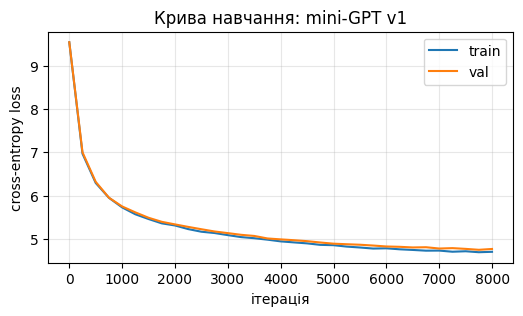

In [54]:
plt.figure(figsize=(6, 3))
plt.plot(model_v1['history']['iter'], model_v1['history']['train'], label="train")
plt.plot(model_v1['history']['iter'], model_v1['history']['val'], label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT v1")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Модель 2

In [55]:
model_v2 = train_variant("minigpt_v2_L8", vocab_size=16000, n_layers=8, max_iters=20000)

[minigpt_v2_L8] Кількість параметрів: 5,703,552
[minigpt_v2_L8] iter     0  train_loss=9.422  val_loss=9.420  (0.1 хв)
[minigpt_v2_L8] iter   250  train_loss=7.075  val_loss=7.083  (0.5 хв)
[minigpt_v2_L8] iter   500  train_loss=6.415  val_loss=6.449  (0.8 хв)
[minigpt_v2_L8] iter   750  train_loss=6.040  val_loss=6.072  (1.2 хв)
[minigpt_v2_L8] iter  1000  train_loss=5.783  val_loss=5.819  (1.5 хв)
[minigpt_v2_L8] iter  1250  train_loss=5.610  val_loss=5.639  (1.9 хв)
[minigpt_v2_L8] iter  1500  train_loss=5.479  val_loss=5.511  (2.2 хв)
[minigpt_v2_L8] iter  1750  train_loss=5.379  val_loss=5.415  (2.6 хв)
[minigpt_v2_L8] iter  2000  train_loss=5.297  val_loss=5.326  (2.9 хв)
[minigpt_v2_L8] iter  2250  train_loss=5.226  val_loss=5.268  (3.3 хв)
[minigpt_v2_L8] iter  2500  train_loss=5.162  val_loss=5.220  (3.6 хв)
[minigpt_v2_L8] iter  2750  train_loss=5.113  val_loss=5.146  (4.0 хв)
[minigpt_v2_L8] iter  3000  train_loss=5.053  val_loss=5.110  (4.4 хв)
[minigpt_v2_L8] iter  3250  t

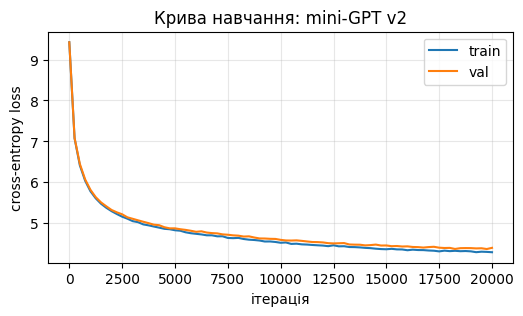

In [56]:
plt.figure(figsize=(6, 3))
plt.plot(model_v2['history']['iter'], model_v2['history']['train'], label="train")
plt.plot(model_v2['history']['iter'], model_v2['history']['val'], label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT v2")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Модель 3

In [57]:
model_v3 = train_variant("minigpt_v3_wide", vocab_size=16000, embed_dim=256, n_heads=8,
                   n_layers=6, context_len=128, learning_rate=1e-3, max_iters=8000)

[minigpt_v3_wide] Кількість параметрів: 12,975,232
[minigpt_v3_wide] iter     0  train_loss=9.431  val_loss=9.430  (0.3 хв)
[minigpt_v3_wide] iter   250  train_loss=6.887  val_loss=6.897  (1.5 хв)
[minigpt_v3_wide] iter   500  train_loss=6.082  val_loss=6.106  (2.7 хв)
[minigpt_v3_wide] iter   750  train_loss=5.632  val_loss=5.668  (4.0 хв)
[minigpt_v3_wide] iter  1000  train_loss=5.363  val_loss=5.416  (5.2 хв)
[minigpt_v3_wide] iter  1250  train_loss=5.202  val_loss=5.242  (6.4 хв)
[minigpt_v3_wide] iter  1500  train_loss=5.074  val_loss=5.126  (7.6 хв)
[minigpt_v3_wide] iter  1750  train_loss=4.970  val_loss=5.017  (8.8 хв)
[minigpt_v3_wide] iter  2000  train_loss=4.876  val_loss=4.935  (10.0 хв)
[minigpt_v3_wide] iter  2250  train_loss=4.809  val_loss=4.875  (11.3 хв)
[minigpt_v3_wide] iter  2500  train_loss=4.732  val_loss=4.808  (12.5 хв)
[minigpt_v3_wide] iter  2750  train_loss=4.674  val_loss=4.756  (13.7 хв)
[minigpt_v3_wide] iter  3000  train_loss=4.638  val_loss=4.721  (14.9

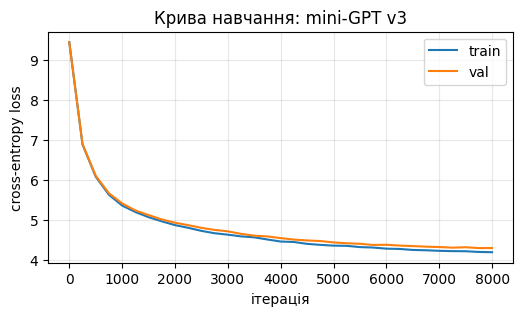

In [58]:
plt.figure(figsize=(6, 3))
plt.plot(model_v3['history']['iter'], model_v3['history']['train'], label="train")
plt.plot(model_v3['history']['iter'], model_v3['history']['val'], label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT v3")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Генерація тексту

In [59]:
from tokenizers import Tokenizer

def load_variant(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device)
    tokenizer = Tokenizer.from_str(ckpt["tokenizer"])
    model = build_model(ckpt["config"])
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model, tokenizer, ckpt["config"]


def generate_text(model, tokenizer, prompt, max_new_tokens=40, temperature=0.8, top_k=40):
    prompt_ids = torch.tensor([tokenizer.encode(prompt).ids], dtype=torch.long, device=device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return tokenizer.decode(out_ids[0].tolist())

model_v1, tok_v1, cfg_v1 = load_variant(os.path.join(MODELS_DIR, "minigpt_v1_L4.pt"))
print("minigpt_v1_L4:")
print(generate_text(model_v1, tok_v1, "Геогра́фія, або заст. земле́пис — система наук, що вивчає"))

print("\nminigpt_v2_L8")
model_v2, tok_v2, cfg_v2 = load_variant(os.path.join(MODELS_DIR, "minigpt_v2_L8.pt"))
print(generate_text(model_v2, tok_v2, "Геогра́фія, або заст. земле́пис — система наук, що вивчає"))

print("\nminigpt_v3_wide")
model_v3, tok_v3, cfg_v3 = load_variant(os.path.join(MODELS_DIR, "minigpt_v3_wide.pt"))
print(generate_text(model_v3, tok_v3, "Геогра́фія, або заст. земле́пис — система наук, що вивчає"))

minigpt_v1_L4:
Геогра́фія, або заст. земле́пис — система наук, що вивчає засоби.

 Біогеографія 
Морецепція (від  — «підготовка», «сух», «і», «вз'язна» та ін. (

minigpt_v2_L8
Геогра́фія, або заст. земле́пис — система наук, що вивчає закони, що вивчає права і знання природи та свободи. Цей метод дозволяє використовувати для збереження і збереження прав людини, на основі якої, як і не з іншого, а не існує, тоді як в теорії

minigpt_v3_wide
Геогра́фія, або заст. земле́пис — система наук, що вивчає, суб'єкт, і є в умовах функціонування і систематичного контролю за допомогою комп'ютера.

Залежно від функції, що характеризує значення для забезпечення роботи в процесі аналізу і оптиміз


## Порівняння

In [60]:
rows = []

from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

def read_best_val(run_name):
    ea = EventAccumulator(os.path.join(RUNS_DIR, run_name), size_guidance={"scalars": 0})
    ea.Reload()
    val_points = ea.Scalars("Loss/val")
    best = min(val_points, key=lambda e: e.value)
    return best.step, best.value

runs = {
    "minigpt_v1_L4":   (model_v1, cfg_v1),
    "minigpt_v2_L8":   (model_v2, cfg_v2),
    "minigpt_v3_wide": (model_v3, cfg_v3),
}

rows = []
for run_name, (m, cfg) in runs.items():
    best_iter, best_val = read_best_val(run_name)
    rows.append({
        "task": "language-modeling",
        "model": run_name,
        "settings": ", ".join(f"{k}={v}" for k, v in cfg.items()),
        "n_params": sum(p.numel() for p in m.parameters()),
        "best_iter": best_iter,
        "val_loss": round(best_val, 3),
        "accuracy": None, "inference_sec": None,
    })

for r in results_data:
    rows.append({
        "task": "sentiment-analysis",
        "model": r["Model"], "settings": "default",
        "n_params": r["Params"],
        "val_loss": None, "accuracy": r["Accuracy"],
        "inference_sec": r.get("Inference time"),
    })

best_params = next(r["Params"] for r in results_data if r["Model"] == best_model_name)
for _, r in df_combined.iterrows():
    rows.append({
        "task": "sentiment-analysis",
        "model": best_model_name,
        "settings": f"max_length={int(r['Max Length'])}, threshold={r['Threshold']}",
        "n_params": best_params,
        "val_loss": None, "accuracy": r["Accuracy"], "inference_sec": None,
    })

df_results = pd.DataFrame(rows)
df_results.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False, encoding="utf-8")
display(df_results)

,task,model,settings,n_params,best_iter,val_loss,accuracy,inference_sec
0,language-modeling,minigpt_v1_L4,"vocab_size=16000, context_len=64, embed_dim=12...",4912000,7750.0,4.753,NaN,NaN
1,language-modeling,minigpt_v2_L8,"vocab_size=16000, context_len=64, embed_dim=12...",5703552,19999.0,4.367,NaN,NaN
2,language-modeling,minigpt_v3_wide,"vocab_size=16000, context_len=128, embed_dim=2...",12975232,7750.0,4.293,NaN,NaN
3,sentiment-analysis,cardiffnlp/twitter-xlm-roberta-base-sentiment,default,278045955,NaN,NaN,0.95,0.322613
4,sentiment-analysis,tabularisai/multilingual-sentiment-analysis,default,135328517,NaN,NaN,0.95,0.120207
5,sentiment-analysis,cardiffnlp/twitter-xlm-roberta-base-sentiment,"max_length=5, threshold=0.5",278045955,NaN,NaN,0.65,NaN
6,sentiment-analysis,cardiffnlp/twitter-xlm-roberta-base-sentiment,"max_length=5, threshold=0.8",278045955,NaN,NaN,0.55,NaN
7,sentiment-analysis,cardiffnlp/twitter-xlm-roberta-base-sentiment,"max_length=5, threshold=0.95",278045955,NaN,NaN,0.50,NaN
8,sentiment-analysis,cardiffnlp/twitter-xlm-roberta-base-sentiment,"max_length=15, threshold=0.5",278045955,NaN,NaN,0.95,NaN
9,sentiment-analysis,cardiffnlp/twitter-xlm-roberta-base-sentiment,"max_length=15, threshold=0.8",278045955,NaN,NaN,0.90,NaN


In [23]:
%load_ext tensorboard
%tensorboard --logdir {RUNS_DIR}

Launching TensorBoard...

## Висновок
За результатами порівняння, найкращий показник val_loss має модель v3 (4,293), далі йдуть v2 (4,367) та базова v1 (4,767). Найбільший вплив на зниження втрат мала зміна архітектурних параметрів моделі. Модель v3 показала найкращий загальний результат завдяки збільшеній "ширині" (розмірність embedding 256, 8 attention-голів) та розширеному розміру контексту до 128 токенів при 6 шарах, навіть за 8000 ітерацій. Модель v2 змогла випередити базову v1 виключно завдяки збільшенню "глибини" (8 шарів замість 4) та значно тривалішому тренуванню у 20 000 ітерацій.

Незважаючи на відчутне покращення математичних метрик, за якістю згенерованого тексту різниця помітна лише частково. Усі три моделі видають текст без глибокого змісту, і жодна не змогла коректно продовжити речення. Базова модель v1 найчастіше зациклюється на коротких фразах як-от «що вивчає». v2 та v3 здатні генерувати граматично правильніші та складніші структури, але так само схильні повторювати одні й ті ж слова та втрачати логічну суть на довших послідовностях.

---
# 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [62]:
%pip install -q gradio

In [22]:
import re
import torch
import gradio as gr
from transformers import pipeline

ner = pipeline(
    "ner",
    model="ukr-models/uk-ner",
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1,
)

TAGS = {
    "PERS": "[ІМ'Я]", "PER": "[ІМ'Я]", "PERSON": "[ІМ'Я]",
    "ORG": "[ОРГ]",
    "LOC": "[МІСЦЕ]", "GPE": "[МІСЦЕ]",
}
MIN_SCORE = 0.5


def split_into_chunks(text, max_chars=600):
    parts = re.split(r"(?<=[.!?\n])", text)
    chunks, current = [], ""
    for part in parts:
        if current and len(current) + len(part) > max_chars:
            chunks.append(current)
            current = ""
        current += part
    if current:
        chunks.append(current)
    return chunks


def anonymize_chunk(chunk):
    entities = ner(chunk)
    for ent in sorted(entities, key=lambda e: e["start"], reverse=True):
        label = ent["entity_group"].split("-")[-1].upper()
        tag = TAGS.get(label)
        if tag and ent["score"] >= MIN_SCORE:
            chunk = chunk[:ent["start"]] + tag + chunk[ent["end"]:]
    return chunk


def anonymize(text):
    if not text or not text.strip():
        return ""
    return "".join(anonymize_chunk(chunk) for chunk in split_into_chunks(text))


EXAMPLE = (
    """
    У Києві Олена Коваль зустрілася з Андрієм Шевченком, Марією Петренко та професором Іваном Бондарем, 
    щоб обговорити спільний проєкт Київського національного університету імені Тараса Шевченка та компанії 
    «Українські Інновації». Після зустрічі вони вирушили до Львова, де планували відвідати Львівську політехніку, 
    Львівський історичний музей і площу Ринок. Наступного дня делегація вирушила до Варшави, де представники Microsoft, 
    Google та Європейської комісії зустрілися з українськими науковцями. 
    Під час конференції Наталія Григоренко з Харкова представила дослідження, проведене спільно з Оксфордським університетом, 
    Массачусетським технологічним інститутом і Національною академією наук України.
    """
)

with gr.Blocks(title="Анонімізатор тексту") as demo:
    gr.Markdown(
        "# Анонімізатор тексту\n"
        "організації на `[ОРГ]`, а місця на `[МІСЦЕ]`."
    )
    inp = gr.Textbox(label="Вихідний текст", value=EXAMPLE, lines=14, max_lines=30,
                     placeholder="Вставте сюди текст…")
    btn = gr.Button("Анонімізувати", variant="primary")
    out = gr.Textbox(label="Анонімізований текст", lines=14, max_lines=30, interactive=False)

    btn.click(anonymize, inputs=inp, outputs=out)

demo.launch(debug=True)

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.37M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c5e985ff7690a1a6d1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://c5e985ff7690a1a6d1.gradio.live


---
### Як здавати лабу

У форму (та сама, що й для попередніх лаб) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```